# Демонстрация работы СППР

Блокнот по шагам показывает работу всех заявленных функций на варианте 1 из практики «Метод Саати»:

| Метод | Что делает |
|---|---|
| AHP (метод Саати) | веса критериев по матрице парных сравнений, проверка согласованности CR < 0,1, итоговая оценка альтернатив |
| TOPSIS | близость альтернативы к идеальному решению с весами из AHP |
| ELECTRE I | индексы согласия и несогласия, отношения превосходства, чистый индекс для ранжирования |
| Парето | отметка недоминируемых альтернатив |

Все расчёты делают функции из `dss/methods.py`, те же, что использует веб-приложение `app.py`. Чтобы запустить блокнот самому: `pip install -r requirements.txt matplotlib jupyter`, затем `jupyter notebook demo.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dss.methods import (DEFAULT_POINTS, ahp_scores, ahp_weights, electre_i, load_variants,
                         matrix_from_upper, pairwise_from_points, pareto_front, rank,
                         read_alternatives, read_csv_any, run_all, spearman, topsis)

pd.set_option("display.precision", 4)

## 1. Данные

Файл `data/variants.csv` содержит все 10 вариантов из листа «Варианты» файла «Метод Саати_stud.xls». Словесные оценки переведены в баллы (шкалы описаны в README): например, риски «низкие» = 1, «недостоверные» = 5. В названии столбца указано направление: `(max)` больше = лучше, `(min)` меньше = лучше.

In [2]:
variants = load_variants("data/variants.csv")
print("Вариантов в файле:", len(variants))
raw = variants[1]
raw

Вариантов в файле: 10


,Проект,Готовность (max),Инвестиции млн руб (min),Срок окупаемости мес (min),Численность команды чел (min),Конкурентная среда (max),Доход млн руб (max),Потенциальный рынок (max),Популярность (max),Риски (min)
0,Проект 1,2,30,24,50,2,22,3,3,5
1,Проект 2,4,10,15,50,2,25,2,3,1
2,Проект 3,3,25,15,40,1,29,2,2,1
3,Проект 4,5,15,12,40,1,29,1,1,4
4,Проект 5,4,20,12,50,2,29,1,2,1


In [3]:
names, X, criteria, directions = read_alternatives(raw)
pd.DataFrame({"Критерий": criteria, "Направление": directions})

,Критерий,Направление
0,Готовность,max
1,Инвестиции млн руб,min
2,Срок окупаемости мес,min
3,Численность команды чел,min
4,Конкурентная среда,max
5,Доход млн руб,max
6,Потенциальный рынок,max
7,Популярность,max
8,Риски,min


## 2. AHP (метод Саати)

### 2.1. Матрица парных сравнений

Важность критериев задана баллами от 1 до 5 (в приложении их можно менять или задать каждое сравнение вручную). Разница баллов переводится в шкалу Саати: 0 → 1, 1 → 3, 2 → 5, 3 → 7, 4 → 9. Ниже диагонали стоят обратные значения.

In [4]:
points = [DEFAULT_POINTS[c] for c in criteria]
print(dict(zip(criteria, points)))
M = pairwise_from_points(points)
pd.DataFrame(M, index=criteria, columns=criteria).round(3)

{'Готовность': 4, 'Инвестиции млн руб': 3, 'Срок окупаемости мес': 2, 'Численность команды чел': 1, 'Конкурентная среда': 3, 'Доход млн руб': 5, 'Потенциальный рынок': 2, 'Популярность': 2, 'Риски': 5}


,Готовность,Инвестиции млн руб,Срок окупаемости мес,Численность команды чел,Конкурентная среда,Доход млн руб,Потенциальный рынок,Популярность,Риски
Готовность,1.000,3.000,5.000,7.0,3.000,0.333,5.000,5.000,0.333
Инвестиции млн руб,0.333,1.000,3.000,5.0,1.000,0.200,3.000,3.000,0.200
Срок окупаемости мес,0.200,0.333,1.000,3.0,0.333,0.143,1.000,1.000,0.143
Численность команды чел,0.143,0.200,0.333,1.0,0.200,0.111,0.333,0.333,0.111
Конкурентная среда,0.333,1.000,3.000,5.0,1.000,0.200,3.000,3.000,0.200
Доход млн руб,3.000,5.000,7.000,9.0,5.000,1.000,7.000,7.000,1.000
Потенциальный рынок,0.200,0.333,1.000,3.0,0.333,0.143,1.000,1.000,0.143
Популярность,0.200,0.333,1.000,3.0,0.333,0.143,1.000,1.000,0.143
Риски,3.000,5.000,7.000,9.0,5.000,1.000,7.000,7.000,1.000


### 2.2. Веса и проверка согласованности

Вес = среднее геометрическое строки, делённое на сумму. λmax = Σ (сумма столбца × вес), CI = (λmax − n) / (n − 1), CR = CI / ПСС (для n = 9 ПСС = 1,45).

In [5]:
w, lam, ci, cr = ahp_weights(M)
print(f"λmax = {lam:.4f}")
print(f"CI   = {ci:.4f}")
print(f"CR   = {cr:.4f}  ->", "суждения согласованы (CR < 0,1)" if cr < 0.1 else "суждения противоречивы, матрицу надо пересмотреть")
pd.Series(w, index=criteria, name="Вес").sort_values(ascending=False).round(4)

λmax = 9.3918
CI   = 0.0490
CR   = 0.0338  -> суждения согласованы (CR < 0,1)


Риски                      0.2853
Доход млн руб              0.2853
Готовность                 0.1535
Инвестиции млн руб         0.0772
Конкурентная среда         0.0772
Потенциальный рынок        0.0347
Срок окупаемости мес       0.0347
Популярность               0.0347
Численность команды чел    0.0173
Name: Вес, dtype: float64

### 2.3. Сверка с примером из методички

Матрица 4×4 из файла «Метод Саати.xls» (лист МАИ). В Excel получены веса 0,3908; 0,3908; 0,1509; 0,0675 и CR = 0,0116.

In [6]:
M_teacher = [[1, 1, 3, 5], [1, 1, 3, 5], [1/3, 1/3, 1, 3], [1/5, 1/5, 1/3, 1]]
w_t, lam_t, ci_t, cr_t = ahp_weights(M_teacher)
print("Веса:", np.round(w_t, 4))
print(f"λmax = {lam_t:.4f}, CI = {ci_t:.4f}, CR = {cr_t:.4f}")

Веса: [0.3908 0.3908 0.1509 0.0675]
λmax = 4.0314, CI = 0.0105, CR = 0.0116


### 2.4. Проверка CR ловит противоречивые суждения

Пример: A в 9 раз важнее B, B в 9 раз важнее C, но C в 9 раз важнее A. Такие суждения противоречат друг другу.

In [7]:
M_bad = matrix_from_upper(3, {(0, 1): 9, (1, 2): 9, (0, 2): 1/9})
_, _, _, cr_bad = ahp_weights(M_bad)
print(f"CR = {cr_bad:.2f}  ->", "согласовано" if cr_bad < 0.1 else "противоречиво, CR ≥ 0,1")

CR = 6.13  -> противоречиво, CR ≥ 0,1


### 2.5. Итоговая оценка альтернатив

Локальный приоритет: для max x / Σx, для min (1/x) / Σ(1/x). Итог S = Σ (вес × приоритет).

In [8]:
s_ahp, P = ahp_scores(X, directions, w)
print("Локальные приоритеты:")
display_P = pd.DataFrame(P, index=names, columns=criteria).round(4)
print(display_P.to_string())
pd.DataFrame({"Оценка AHP": s_ahp, "Место": rank(s_ahp)}, index=names)

Локальные приоритеты:
          Готовность  Инвестиции млн руб  Срок окупаемости мес  Численность команды чел  Конкурентная среда  Доход млн руб  Потенциальный рынок  Популярность   Риски
Проект 1      0.1111              0.1149                0.1220                   0.1818               0.250         0.1642               0.3333        0.2727  0.0580
Проект 2      0.2222              0.3448                0.1951                   0.1818               0.250         0.1866               0.2222        0.2727  0.2899
Проект 3      0.1667              0.1379                0.1951                   0.2273               0.125         0.2164               0.2222        0.1818  0.2899
Проект 4      0.2778              0.2299                0.2439                   0.2273               0.125         0.2164               0.1111        0.0909  0.0725
Проект 5      0.2222              0.1724                0.2439                   0.1818               0.250         0.2164               0.1111     

,Оценка AHP,Место
Проект 1,0.1370,5
Проект 2,0.2431,1
Проект 3,0.2151,3
Проект 4,0.1719,4
Проект 5,0.2330,2


## 3. TOPSIS

Векторная нормировка r = x / √Σx², взвешивание v = w · r (веса из AHP), идеал и антиидеал с учётом направления критерия, расстояния D⁺ и D⁻, близость C = D⁻ / (D⁺ + D⁻).

In [9]:
c, d_plus, d_minus = topsis(X, directions, w)
pd.DataFrame({"D+": d_plus, "D-": d_minus, "C": c, "Место": rank(c)}, index=names)

,D+,D-,C,Место
Проект 1,0.1869,0.0293,0.1355,5
Проект 2,0.0277,0.1815,0.8674,1
Проект 3,0.0498,0.1769,0.7801,3
Проект 4,0.1326,0.0819,0.3819,4
Проект 5,0.0300,0.1814,0.8579,2


## 4. ELECTRE I

* Согласие C(a, b): сумма весов критериев, по которым a не хуже b.
* Несогласие D(a, b): наибольший проигрыш a по одному критерию, делённый на размах этого критерия.
* a превосходит b, если C(a, b) ≥ порога согласия и D(a, b) ≤ порога несогласия.
* Чистый индекс для полного ранжирования: (ΣC отдано − ΣC получено) − (ΣD отдано − ΣD получено).

In [10]:
c_thr, d_thr = 0.6, 0.75
net, out, C, D, kernel = electre_i(X, directions, w, c_thr, d_thr)
print("Индекс согласия C(a, b):")
pd.DataFrame(C, index=names, columns=names).round(2)

Индекс согласия C(a, b):


,Проект 1,Проект 2,Проект 3,Проект 4,Проект 5
Проект 1,0.00,0.16,0.15,0.15,0.16
Проект 2,0.97,0.00,0.70,0.51,0.68
Проект 3,0.85,0.66,0.00,0.73,0.66
Проект 4,0.85,0.49,0.65,0.00,0.60
Проект 5,0.93,0.85,0.95,0.75,0.00


In [11]:
print("Индекс несогласия D(a, b):")
pd.DataFrame(D, index=names, columns=names).round(2)

Индекс несогласия D(a, b):


,Проект 1,Проект 2,Проект 3,Проект 4,Проект 5
Проект 1,0.0,1.0,1.00,1.00,1.00
Проект 2,0.5,0.0,1.00,1.00,0.57
Проект 3,1.0,1.0,0.00,0.67,1.00
Проект 4,1.0,1.0,0.75,0.00,1.00
Проект 5,1.0,0.5,1.00,1.00,0.00


In [12]:
print(f"Пороги: согласие >= {c_thr}, несогласие <= {d_thr}")
print("Отношения превосходства:")
for i in range(len(names)):
    for j in range(len(names)):
        if out[i, j]:
            print(f"  {names[i]} превосходит {names[j]}  (C = {C[i, j]:.2f}, D = {D[i, j]:.2f})")
print("Ядро (кого никто не превосходит):", [n for n, k in zip(names, kernel) if k] or "пусто: есть взаимные превосходства")
pd.DataFrame({"Чистый индекс": net, "Место": rank(net)}, index=names)

Пороги: согласие >= 0.6, несогласие <= 0.75
Отношения превосходства:
  Проект 2 превосходит Проект 1  (C = 0.97, D = 0.50)
  Проект 2 превосходит Проект 5  (C = 0.68, D = 0.57)
  Проект 3 превосходит Проект 4  (C = 0.73, D = 0.67)
  Проект 4 превосходит Проект 3  (C = 0.65, D = 0.75)
  Проект 5 превосходит Проект 2  (C = 0.85, D = 0.50)
Ядро (кого никто не превосходит): пусто: есть взаимные превосходства


,Чистый индекс,Место
Проект 1,-3.4812,5
Проект 2,1.1148,2
Проект 3,0.5488,3
Проект 4,0.3665,4
Проект 5,1.4511,1


Пороги влияют на отношения превосходства. При строгих порогах отношений меньше:

In [13]:
for ct, dt in [(0.6, 0.75), (0.7, 0.6), (0.8, 0.5)]:
    _, o, *_ = electre_i(X, directions, w, ct, dt)
    print(f"согласие >= {ct}, несогласие <= {dt}: отношений превосходства {int(o.sum())}")

согласие >= 0.6, несогласие <= 0.75: отношений превосходства 5
согласие >= 0.7, несогласие <= 0.6: отношений превосходства 2
согласие >= 0.8, несогласие <= 0.5: отношений превосходства 2


## 5. Парето

Альтернатива доминируется, если другая не хуже по всем критериям и лучше хотя бы по одному. На 9 критериях каждый проект хоть в чём-то лучше остальных, поэтому все недоминируемы. На трёх критериях (инвестиции, доход, риски) видно, как метод отсекает доминируемые проекты.

In [14]:
par9 = pareto_front(X, directions)
idx = [criteria.index(k) for k in ["Инвестиции млн руб", "Доход млн руб", "Риски"]]
par3 = pareto_front(X[:, idx], [directions[k] for k in idx])
pd.DataFrame({"Парето, 9 критериев": np.where(par9, "недоминируемая", "доминируемая"),
              "Парето, 3 критерия": np.where(par3, "недоминируемая", "доминируемая")}, index=names)

,"Парето, 9 критериев","Парето, 3 критерия"
Проект 1,недоминируемая,доминируемая
Проект 2,недоминируемая,недоминируемая
Проект 3,недоминируемая,доминируемая
Проект 4,недоминируемая,недоминируемая
Проект 5,недоминируемая,недоминируемая


## 6. Сводный рейтинг трёх методов

In [15]:
table, *_ = run_all(names, X, directions, w)
print(f"Спирмен AHP и TOPSIS:    {spearman(table['AHP'], table['TOPSIS']):.2f}")
print(f"Спирмен AHP и ELECTRE:   {spearman(table['AHP'], table['ELECTRE (чистый индекс)']):.2f}")
print(f"Спирмен TOPSIS и ELECTRE: {spearman(table['TOPSIS'], table['ELECTRE (чистый индекс)']):.2f}")
best = table.sort_values(["Средний ранг", "Место TOPSIS"]).iloc[0]["Альтернатива"]
print("Рекомендация (лучший средний ранг):", best)
table.round(4)

Спирмен AHP и TOPSIS:    1.00
Спирмен AHP и ELECTRE:   0.90
Спирмен TOPSIS и ELECTRE: 0.90
Рекомендация (лучший средний ранг): Проект 2


,Альтернатива,AHP,Место AHP,TOPSIS,Место TOPSIS,ELECTRE (чистый индекс),Место ELECTRE,Ядро ELECTRE,Парето,Средний ранг
0,Проект 1,0.1370,5,0.1355,5,-3.4812,5,False,True,5.0000
1,Проект 2,0.2431,1,0.8674,1,1.1148,2,False,True,1.3333
2,Проект 3,0.2151,3,0.7801,3,0.5488,3,False,True,3.0000
3,Проект 4,0.1719,4,0.3819,4,0.3665,4,False,True,4.0000
4,Проект 5,0.2330,2,0.8579,2,1.4511,1,False,True,1.6667


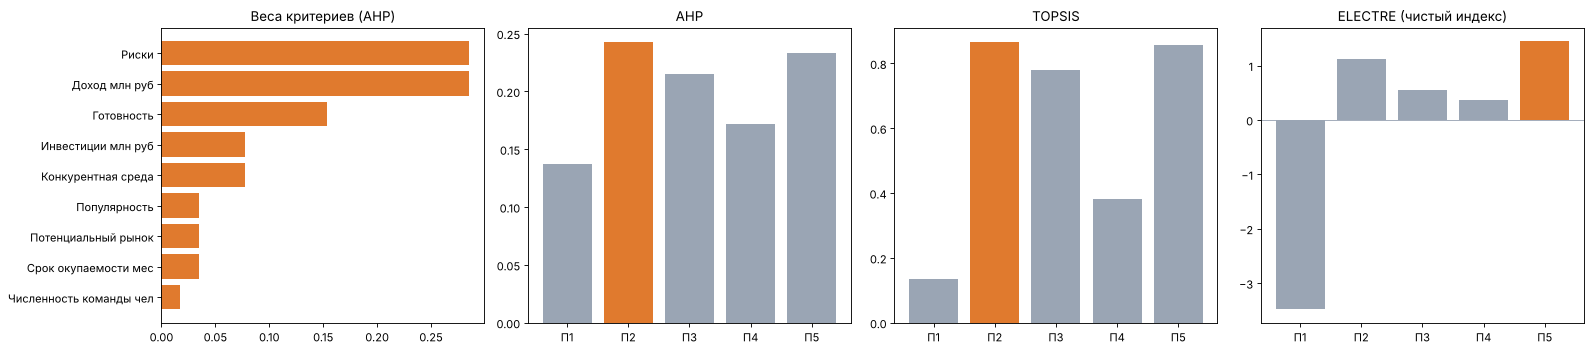

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
order = np.argsort(w)
axes[0].barh([criteria[i] for i in order], w[order], color="#E07A2E")
axes[0].set_title("Веса критериев (AHP)")
for ax, col in zip(axes[1:], ["AHP", "TOPSIS", "ELECTRE (чистый индекс)"]):
    vals = table[col].to_numpy()
    ax.bar([n.replace("Проект ", "П") for n in names], vals,
           color=["#E07A2E" if v == vals.max() else "#9AA5B4" for v in vals])
    ax.axhline(0, color="#9AA5B4", lw=0.8)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 7. Чувствительность: что если риски менее важны

Снижаем важность рисков с 5 до 2 баллов и пересчитываем все методы.

In [17]:
pts2 = dict(DEFAULT_POINTS, **{"Риски": 2})
w2, _, _, cr2 = ahp_weights(pairwise_from_points([pts2[c] for c in criteria]))
table2, *_ = run_all(names, X, directions, w2)
print(f"Вес рисков: {w[criteria.index('Риски')]:.3f} -> {w2[criteria.index('Риски')]:.3f}, CR = {cr2:.4f}")
pd.DataFrame({
    "AHP до": table["Место AHP"].values, "AHP после": table2["Место AHP"].values,
    "TOPSIS до": table["Место TOPSIS"].values, "TOPSIS после": table2["Место TOPSIS"].values,
    "ELECTRE до": table["Место ELECTRE"].values, "ELECTRE после": table2["Место ELECTRE"].values,
}, index=names)

Вес рисков: 0.285 -> 0.045, CR = 0.0341


,AHP до,AHP после,TOPSIS до,TOPSIS после,ELECTRE до,ELECTRE после
Проект 1,5,5,5,5,5,5
Проект 2,1,1,1,1,2,3
Проект 3,3,4,3,4,3,4
Проект 4,4,3,4,2,4,2
Проект 5,2,2,2,3,1,1


## 8. Свои данные из CSV

Приложение принимает любой CSV: первый столбец названия, дальше числовые критерии. Подходит и файл из русского Excel (разделитель «;», дробная часть через запятую, кодировка Windows-1251). Ниже условный пример с тремя ноутбуками, только для проверки чтения файла.

In [18]:
csv_bytes = ("Ноутбук;Цена руб (min);Вес кг (min);Автономность ч (max)\n"
             "Модель A;55000;1,6;8\n"
             "Модель B;72000;1,3;12\n"
             "Модель C;48000;2,1;6\n").encode("cp1251")
own = read_csv_any(csv_bytes)
n2, X2, crit2, dirs2 = read_alternatives(own)
w_eq = np.ones(len(crit2)) / len(crit2)     # равные веса для примера
t_own, *_ = run_all(n2, X2, dirs2, w_eq)
t_own[["Альтернатива", "AHP", "Место AHP", "TOPSIS", "Место TOPSIS", "Место ELECTRE", "Парето"]].round(3)

,Альтернатива,AHP,Место AHP,TOPSIS,Место TOPSIS,Место ELECTRE,Парето
0,Модель A,0.329,2,0.487,2,2,True
1,Модель B,0.378,1,0.668,1,1,True
2,Модель C,0.293,3,0.332,3,3,True


Ошибки в данных не ломают программу, а дают понятное сообщение:

In [19]:
bad_files = {
    "текст вместо числа": "Имя,Цена (min),Вес (min)\nA,дорого,1\nB,100,2\n",
    "ноль в данных": "Имя,Цена (min),Вес (min)\nA,0,1\nB,100,2\n",
    "одна альтернатива": "Имя,Цена,Вес\nA,10,1\n",
}
for title, text in bad_files.items():
    try:
        read_alternatives(read_csv_any(text.encode("utf-8")))
    except ValueError as e:
        print(f"{title}: {e}")

текст вместо числа: В столбцах есть пустые или нечисловые значения: ['Цена (min)']
ноль в данных: Все значения критериев должны быть больше нуля.
одна альтернатива: Нужно минимум две альтернативы.
